# Прогноз сроков доставки: проверка данных и сравнение моделей

**Задача.** Проверить, можно ли прогнозировать срок доставки по признакам заказа: размеру корзины, её стоимости и способу оплаты. Заодно оценить качество выгрузки. 

**Главный результат:** более сложные модели не улучшили простой прогноз средним. Причём неоднозначные даты доставки существенно влияют на целевую переменную. Ниже показаны расчёты.

## 1. Подготовка данных и проверка качества

Для заказов с несколькими датами доставки первоначально выбираем последнюю дату, а затем оцениваем, как изменятся показатели при выборе первой. Это позволяет проверить устойчивость целевой переменной к способу агрегации.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

orders_raw = pd.read_csv('orders_products.csv')
delivery_raw = pd.read_csv('delivery.csv')
orders_raw['order_dt'] = pd.to_datetime(orders_raw['order_dt'], dayfirst=True)
delivery_raw['delivery_dt'] = pd.to_datetime(delivery_raw['delivery_dt'], dayfirst=True)
print('Строки в заказах:', len(orders_raw), 'в доставках:', len(delivery_raw))
print('Полные дубликаты записей о доставках:', delivery_raw.duplicated().sum())
print('Заказы с несколькими разными датами:', (delivery_raw.groupby('order_id').delivery_dt.nunique() > 1).sum())

Строки в заказах: 5990 в доставках: 1511
Полные дубликаты записей о доставках: 6
Заказы с несколькими разными датами: 282


## 2. Одна строка на заказ

В `orders_products.csv` каждая строка — товарная позиция. Для регрессии суммируем единицы, посчитаем разные товары и общую стоимость. У доставки может быть несколько дат. Так как неизвестно, почему они отличаются, это **проблема качества**, а не доказательство повторной доставки.

In [2]:
orders_raw['line_sum'] = orders_raw['amount'] * orders_raw['Price']
orders = (orders_raw.groupby(['order_id', 'order_dt', 'payment_method'], as_index=False)
          .agg(products_amount=('amount', 'sum'),
               products_count=('product_id', 'nunique'),
               order_sum=('line_sum', 'sum')))
delivery_unique = delivery_raw.drop_duplicates()
delivery = (delivery_unique.groupby('order_id', as_index=False)
            .agg(delivery_dt=('delivery_dt', 'max'),
                 earliest_dt=('delivery_dt', 'min'),
                 dates_count=('delivery_dt', 'nunique')))
df = orders.merge(delivery, on='order_id', how='inner')
df['delivery_days'] = (df['delivery_dt'] - df['order_dt']).dt.days
df['earliest_delivery_days'] = (df['earliest_dt'] - df['order_dt']).dt.days
print('Заказов в итоговой выборке:', len(df))
print('Заказов с неоднозначными датами в итоговой выборке:', (df.dates_count > 1).sum())
print('Среднее (последняя дата):', round(df.delivery_days.mean(), 2), 'дня')
print('Среднее (первая дата):', round(df.earliest_delivery_days.mean(), 2), 'дня')
print('Пропущенных значений в модели:', int(df[['payment_method','products_amount','products_count','order_sum','delivery_days']].isna().sum().sum()))
display(df[['order_dt','payment_method','products_count','products_amount','order_sum','delivery_days']].head())

Заказов в итоговой выборке: 1046
Заказов с неоднозначными датами в итоговой выборке: 250
Среднее (последняя дата): 32.67 дня
Среднее (первая дата): 27.59 дня
Пропущенных значений в модели: 0


,order_dt,payment_method,products_count,products_amount,order_sum,delivery_days
0,2020-02-26,online,1,41,615000,60
1,2021-04-23,online,4,138,39640,45
2,2022-09-13,offline,2,69,21960,51
3,2020-04-22,offline,3,80,13950,8
4,2020-08-30,online,2,77,540900,43


## 3. Прогноз срока доставки

Цель — `delivery_days`, задача регрессии. Оцениваем **RMSE в днях**, сравнивая каждую модель с базовой стратегией «предсказывать средний срок». Все модели проходят одинаковую 5-кратную кросс-валидацию. Кодирование категорий и масштабирование производятся внутри `Pipeline`, чтобы избежать утечки при оценке.

In [3]:
X = df[['payment_method', 'products_amount', 'products_count', 'order_sum']]
y = df['delivery_days']
preprocess = ColumnTransformer([
    ('scaler', StandardScaler(), ['products_amount','products_count','order_sum']),
    ('ohe', OneHotEncoder(handle_unknown='ignore'), ['payment_method'])
])
models = {
    'Средний срок (baseline)': DummyRegressor(strategy='mean'),
    'Линейная регрессия': LinearRegression(),
    'Дерево решений (глубина 5)': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Случайный лес': RandomForestRegressor(n_estimators=50, min_samples_leaf=5, n_jobs=1, random_state=42),
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    pipeline = Pipeline([('preprocess', preprocess), ('model', model)])
    rmse_per_fold = -cross_val_score(pipeline, X, y, scoring='neg_root_mean_squared_error', cv=cv)
    rows.append({'model': name, 'RMSE, дни': np.sqrt(np.mean(rmse_per_fold ** 2))})
results = pd.DataFrame(rows).sort_values('RMSE, дни')
display(results.round(2))

,model,"RMSE, дни"
0,Средний срок (baseline),17.29
1,Линейная регрессия,17.39
2,Дерево решений (глубина 5),17.94
3,Случайный лес,18.19


## 4. Визуализация результатов

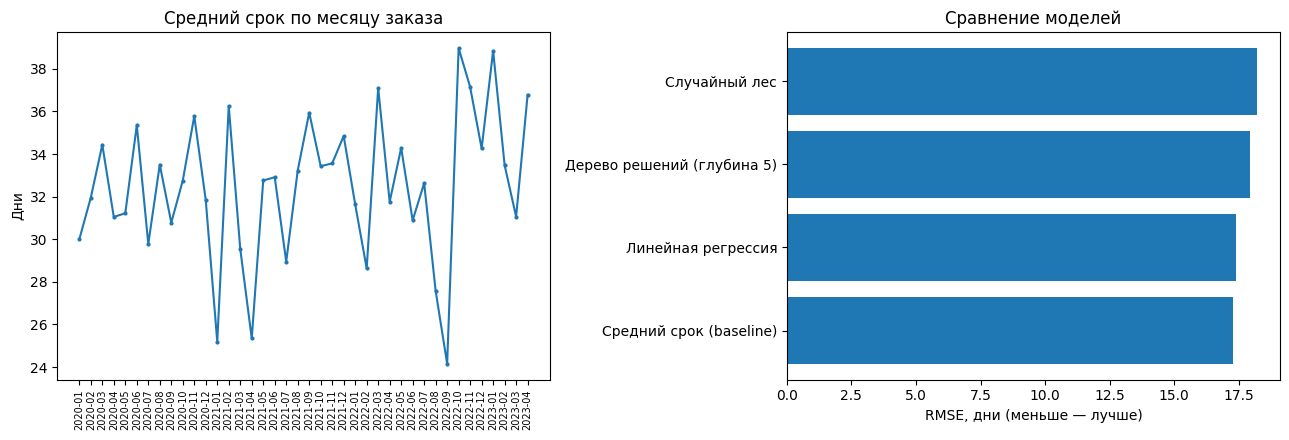

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
monthly = df.groupby(df.order_dt.dt.to_period('M')).delivery_days.agg(['count', 'mean']).reset_index()
monthly['month'] = monthly['order_dt'].astype(str)
axes[0].plot(monthly.month, monthly['mean'], marker='o', markersize=2)
axes[0].set_title('Средний срок по месяцу заказа')
axes[0].set_ylabel('Дни')
axes[0].tick_params(axis='x', labelrotation=90, labelsize=7)
axes[1].barh(results['model'], results['RMSE, дни'])
axes[1].set_xlabel('RMSE, дни (меньше — лучше)')
axes[1].set_title('Сравнение моделей')
fig.tight_layout()
plt.show()

## 5. Выводы

1. В итоговой выборке **1 046 заказов**, средний срок доставки по выбранному правилу — **32,67 дня**.
2. На исходных 1 511 записях доставки обнаружено **282 заказа с несколькими датами**. Из них **250** вошли в сопоставленную выборку. При выборе первой даты средний срок становится **27,59 дня**. Причина расхождений неизвестна, поэтому модель требует доуточнения источника.
3. Прогноз средним (RMSE **17,29 дня**) оказался лучше линейной регрессии (**17,39**), ограниченного дерева (**17,94**) и случайного леса (**18,19**).
4. Это означает, что в рамках данных и выбранной схемы проверки признаки корзины и оплаты не обеспечили измеримого улучшения прогноза. **Не рекомендовал бы использовать такую модель для обещания сроков клиентам** без сведений о логистике, расстоянии, загрузке склада, маршруте и корректного определения даты доставки.

Вывод относится к имеющейся выборке и выбранным признакам; для оценки фактических сроков в рабочем процессе потребуется уточнить природу дат и состав признаков.